<a href="https://colab.research.google.com/github/kralsolomon/slm_assignment/blob/main/assignment2_finetune_slm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: Fine-tune a small language model (Qwen3-1.7B + LoRA)

**Narrow skill:** read a customer-support ticket (ru / kk / en / mixed) and answer with exactly one JSON object
`{"category": ..., "urgency": 0-2, "escalate": true/false}`. This is the Assignment 1 task, so the result can be compared with Jev.

**Runtime:** Runtime → Change runtime type → **T4 GPU**. **Key:** add `OPENROUTER_API_KEY` under Colab → Secrets (used to generate and check training data, and nothing else).

In [1]:
%pip -q install unsloth openai
import os, sys
from google.colab import userdata
os.environ['OPENROUTER_API_KEY'] = userdata.get('OPENROUTER_API_KEY')
if not os.path.exists('slm.py'):
    # TODO: replace with your repo URL (or upload slm.py and data/ through the Colab file sidebar)
    !git clone https://github.com/kralsolomon/slm_assignment.git repo && cp -r repo/* .
os.makedirs('results', exist_ok=True)
!nvidia-smi -L

Cloning into 'repo'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 13 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (13/13), 19.04 KiB | 9.52 MiB/s, done.
Resolving deltas: 100% (2/2), done.
GPU 0: Tesla T4 (UUID: GPU-6ee7c315-6d1c-7383-4dd7-974bd0066928)


## 1. Model choice

*(Draft, rewrite in your own words.)* I chose **Qwen3-1.7B**. It is on the allowed list, small enough to LoRA-train on a free T4 in minutes and to run in LM Studio on a laptop,
and Qwen3 is advertised as multilingual (119 languages), which matters for Russian and Kazakh tickets. The 4B version would likely be more accurate, but is slower to train, slower to run, and the task is narrow.

## 2. Task and test set

Test set: the 80 tickets from Assignment 1 with **your reviewed labels** (`data/test_tickets.csv`). They are never used for training.
Metrics: % valid JSON, route accuracy (escalate → `human`, otherwise the category), category / urgency / escalate accuracy, and exact match of all three fields.

In [2]:
import unsloth                                   # must be imported before trl / transformers
from unsloth import FastLanguageModel
import gc, json, torch, pandas as pd
from datasets import Dataset
import slm as S
pd.set_option('display.max_colwidth', 140, 'display.width', 220)

test = S.load_test('data/test_tickets.csv')
print(len(test), 'test tickets;', test['lang'].value_counts().to_dict())

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1111 14:43:48.474000 317 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1111 14:43:48.517000 317 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
80 test tickets; {'ru': 36, 'en': 20, 'kk': 14, 'mix': 10}


## 3. Dataset: generate with a bigger LLM, then clean

1. **Generate** with Claude Sonnet 5.5: one call per (category × urgency/escalate combination × language) cell, 10 tickets each, with the intended labels.
2. **Clean:** drop too short / too long texts, exact duplicates, near-duplicates (5-gram Jaccard ≥ 0.8) and anything too similar to a test ticket (≥ 0.6, to prevent leakage).
3. **Verify labels:** Claude labels every ticket blindly; a ticket is kept only if its label matches all three intended fields. This removes ambiguous or mislabeled examples.

In [3]:
GEN_MODEL = 'anthropic/claude-sonnet-5.5'   # OpenRouter model id
client = S.make_client()
raw = S.generate_raw(client, GEN_MODEL, n_per_cell=10)       # 4 categories x 5 combos x 4 languages x 10 = 800 target
raw.to_csv('data/raw_generated.csv', index=False)
print(len(raw), 'raw tickets')

800 raw tickets


In [4]:
train_df, stats = S.clean_dataset(raw, test, client=client, verify_model=GEN_MODEL, max_rows=1000)
print(json.dumps(stats, indent=2, ensure_ascii=False))
assert len(train_df) >= 300, 'fewer than 300 clean rows: raise n_per_cell above and rerun'
S.write_jsonl(train_df, 'data/train.jsonl')
S.write_jsonl(test.assign(instruction=test['text'])[['id','instruction','output','lang','category','urgency','escalate']], 'data/test.jsonl')
json.dump(stats, open('results/dataset_cleaning_stats.json', 'w'), indent=2, ensure_ascii=False)
sample = train_df.sample(20, random_state=1)
sample.to_csv('results/dataset_sample_20.csv', index=False)
sample

{
  "raw": 800,
  "after_length_filter(8-600 chars)": 800,
  "after_exact_dedup": 797,
  "after_near_dup(>=0.8) and test_leak(>=0.6)": 797,
  "label_check_disagreed": 369,
  "after_label_verification": 428,
  "final_train_rows": 428,
  "by_language": {
    "ru": 113,
    "kk": 105,
    "mix": 105,
    "en": 105
  },
  "by_category": {
    "billing": 124,
    "delivery": 118,
    "account": 110,
    "technical": 76
  },
  "escalate_share": 0.25
}


,instruction,output,lang,category,urgency,escalate
227,"Сәлеметсіз бе! Приложение вылетает каждый раз, когда нажимаю «Оплатить», заказ №48213 на 27 500 тг. Акция заканчивается через 2 часа, по...","{""category"": ""technical"", ""urgency"": 2, ""escalate"": false}",mix,technical,2,False
208,"Привезли холодильник с вмятиной на двери, заказ №31877, 189 000 ₸. Курьер ещё стоит у подъезда. Принимать или отказываться от заказа?","{""category"": ""delivery"", ""urgency"": 2, ""escalate"": false}",ru,delivery,2,False
164,"Сәлем, хочу отменить заказ #558201 пока он не передан курьеру, там 42 500 ₸ с кошелька. Успею ещё? Керек емес болып қалды","{""category"": ""delivery"", ""urgency"": 2, ""escalate"": false}",mix,delivery,2,False
277,"Здравствуйте. Хотел бы узнать, можно ли изменить имя и фамилию в личном кабинете? При регистрации ошибся в одной букве, не критично, но ...","{""category"": ""account"", ""urgency"": 0, ""escalate"": false}",mix,account,0,False
62,"Слушайте, вы серьезно просите пароль минимум 12 символов с заглавной буквой и спецсимволом?? Я же не банк открываю, а просто за картошко...","{""category"": ""account"", ""urgency"": 0, ""escalate"": false}",mix,account,0,False
172,"I was charged 48,900 KZT twice for order #KZ-7731204 and I never placed the second order. Please block my card and call me ASAP.","{""category"": ""billing"", ""urgency"": 2, ""escalate"": true}",en,billing,2,True
328,"Отличный сервис: курьер «доставил» мой заказ на 87 500 тг, при этом я весь день сидел дома и никто не приходил. Видимо, посылка телепорт...","{""category"": ""delivery"", ""urgency"": 2, ""escalate"": false}",ru,delivery,2,False
4,"Сәлеметсіз бе! Кеше #48213 тапсырыс бойынша 2 500 теңге кэшбэк түсуі керек еді, бірақ әлі көрінбейді. Қашан түсетінін айтып бере аласызд...","{""category"": ""billing"", ""urgency"": 0, ""escalate"": false}",kk,billing,0,False
242,"Why was I charged 14,990 tg twice for the same order?? One payment went through from my Kaspi card and then another one from the wallet ...","{""category"": ""billing"", ""urgency"": 1, ""escalate"": false}",en,billing,1,False
382,"Ну конечно, промокод NEWYEAR15 ""действует на все товары"", а при оформлении пишет, что не подходит. Прекрасная акция, просто супер. Заказ...","{""category"": ""billing"", ""urgency"": 1, ""escalate"": false}",ru,billing,1,False


## 4. "Before": the base model on the test set

In [5]:
MODEL_NAME = 'unsloth/Qwen3-1.7B-unsloth-bnb-4bit'
MAX_LEN = 1024

def load_base():
    return FastLanguageModel.from_pretrained(MODEL_NAME, max_seq_length=MAX_LEN, load_in_4bit=True)

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

model, tokenizer = load_base()
assert tokenizer.eos_token == '<|im_end|>'
FastLanguageModel.for_inference(model)
base_out, base_lat = S.run_model(model, tokenizer, list(test['text']))
base_metrics = S.evaluate(test, base_out, base_lat)
json.dump(base_out, open('results/before_outputs.json', 'w'), ensure_ascii=False, indent=1)
del model, tokenizer; free_gpu()
base_metrics

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

{'n': 80,
 'valid_json_pct_strict': 33.75,
 'valid_json_pct': 100.0,
 'route_acc': 0.325,
 'category_acc': 0.85,
 'urgency_acc': 0.45,
 'escalate_acc': 0.3625,
 'exact_match': 0.25,
 'latency_mean_s': 0.44919630908750036}

## 5. Fine-tune with LoRA (QLoRA: 4-bit base + LoRA adapters)

Loss is computed on the answer only (`train_on_responses_only`). The training text is exactly the inference prompt followed by the JSON answer, so train and test prompts match.

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth 2026.11.3 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/428 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/428 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 428 | Num Epochs = 2 | Total steps = 54
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 2 x 1) = 16
 "-____-"     Trainable parameters = 17,432,576 of 1,738,007,552 (1.00% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
1,0.586274
2,0.936809
3,0.679157
4,0.436821
5,0.279635
6,0.323094
7,0.182688
8,0.059991
9,0.186366
10,0.108095


Unsloth: Restored added_tokens_decoder metadata in outputs_main/checkpoint-54/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in lora_main/tokenizer_config.json.
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to h

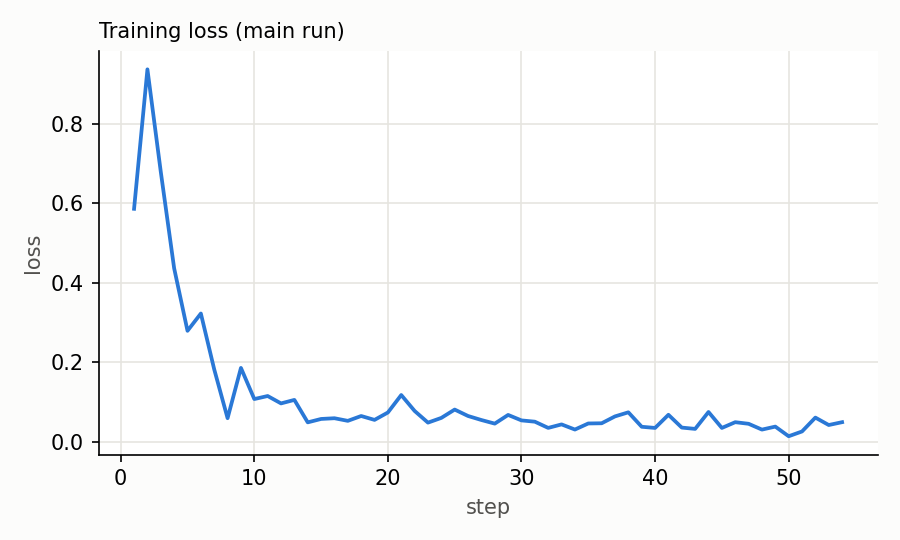

In [6]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bf16_supported
from unsloth.chat_templates import train_on_responses_only

def train_and_eval(name, rows, r=16, alpha=16, lr=2e-4, epochs=2, seed=3407, keep_model=False):
    model, tokenizer = load_base()
    model = FastLanguageModel.get_peft_model(
        model, r=r, lora_alpha=alpha, lora_dropout=0, bias='none',
        target_modules=['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
        use_gradient_checkpointing='unsloth', random_state=seed)
    ds = Dataset.from_list([{'text': S.training_text(tokenizer, x['instruction'], x['output'])} for x in rows])
    hp = dict(name=name, model=MODEL_NAME, n_train=len(rows), lora_r=r, lora_alpha=alpha, learning_rate=lr, epochs=epochs,
              batch_size=8, grad_accum=2, optimizer='adamw_8bit', max_seq_length=MAX_LEN, seed=seed)
    args = SFTConfig(dataset_text_field='text', per_device_train_batch_size=8, gradient_accumulation_steps=2,
                     num_train_epochs=epochs, learning_rate=lr, warmup_steps=5, logging_steps=1, optim='adamw_8bit',
                     weight_decay=0.01, lr_scheduler_type='linear', seed=seed, report_to='none',
                     fp16=not is_bf16_supported(), bf16=is_bf16_supported(), output_dir=f'outputs_{name}')
    trainer = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=ds, args=args)
    trainer = train_on_responses_only(trainer, instruction_part='<|im_start|>user\n',
                                      response_part='<|im_start|>assistant\n<think>\n\n</think>\n\n')
    trainer.train()
    log = trainer.state.log_history
    if keep_model:
        model.save_pretrained(f'lora_{name}'); tokenizer.save_pretrained(f'lora_{name}')
    FastLanguageModel.for_inference(model)
    out, lat = S.run_model(model, tokenizer, list(test['text']))
    metrics = S.evaluate(test, out, lat)
    del model, tokenizer, trainer; free_gpu()
    return dict(hp=hp, log=log, outputs=out, metrics=metrics)

rows = S.read_jsonl('data/train.jsonl')
main = train_and_eval('main', rows, r=16, alpha=16, lr=2e-4, epochs=2, keep_model=True)
json.dump(main['hp'], open('results/hyperparameters_main.json', 'w'), indent=2)
json.dump(main['outputs'], open('results/after_outputs.json', 'w'), ensure_ascii=False, indent=1)
S.plot_loss(main['log'], 'results/loss_curve_main.png', 'Training loss (main run)')
from IPython.display import Image; Image('results/loss_curve_main.png')

## 6. Evaluation: before vs after

In [7]:
table = pd.DataFrame({'base (before)': base_metrics, 'fine-tuned (after)': main['metrics']}).T
table.to_csv('results/before_after_metrics.csv')
display(table.round(3))
cmp10 = S.side_by_side(test, base_out, main['outputs'])
cmp10.to_csv('results/side_by_side_10.csv', index=False)
cmp10

,n,valid_json_pct_strict,valid_json_pct,route_acc,category_acc,urgency_acc,escalate_acc,exact_match,latency_mean_s
base (before),80.0,33.75,100.0,0.325,0.850,0.450,0.362,0.25,0.449
fine-tuned (after),80.0,100.00,100.0,0.925,0.962,0.775,0.962,0.75,0.438


,id,ticket,gold,base,base_correct,fine_tuned,fine_tuned_correct
0,T069,"Мой аккаунт взломали! С него заказали товары на 120 000 тенге, пароль не подходит. Срочно блокируйте!","{""category"": ""account"", ""urgency"": 2, ""escalate"": true}","```json\n{\n ""category"": ""account"",\n ""urgency"": 2,\n ""escalate"": true\n}\n```",True,"{""category"": ""account"", ""urgency"": 2, ""escalate"": true}",True
1,T042,Driver was drunk and almost hit my car while delivering. I have the plate number and will report this to the police.,"{""category"": ""delivery"", ""urgency"": 2, ""escalate"": true}","```json\n{\n ""category"": ""delivery"",\n ""urgency"": 2,\n ""escalate"": true\n}\n```",True,"{""category"": ""delivery"", ""urgency"": 2, ""escalate"": true}",True
2,T071,I'm locked out of my account after too many attempts. I need to access my order today for a return deadline.,"{""category"": ""account"", ""urgency"": 2, ""escalate"": false}","{""category"": ""account"", ""urgency"": 2, ""escalate"": true}",False,"{""category"": ""account"", ""urgency"": 2, ""escalate"": false}",True
3,T043,"Приложение вылетает сразу после запуска на iPhone 13, iOS 17.","{""category"": ""technical"", ""urgency"": 1, ""escalate"": false}","```json\n{""category"": ""technical"", ""urgency"": 2, ""escalate"": true}\n```",False,"{""category"": ""technical"", ""urgency"": 2, ""escalate"": false}",False
4,T068,"Аккаунтыма кіре алмай жатырмын, пароль қате дейді, но я только что его менял.","{""category"": ""account"", ""urgency"": 1, ""escalate"": false}","```json\n{""category"": ""account"", ""urgency"": 1, ""escalate"": true}\n```",False,"{""category"": ""account"", ""urgency"": 1, ""escalate"": false}",True
5,T021,"Курьер должен был приехать вчера, заказ 60321 до сих пор не доставлен.","{""category"": ""delivery"", ""urgency"": 1, ""escalate"": false}","{""category"": ""delivery"", ""urgency"": 2, ""escalate"": true}",False,"{""category"": ""delivery"", ""urgency"": 1, ""escalate"": false}",True
6,T048,"Қосымшада фото жүктей алмаймын, ошибка «upload failed».","{""category"": ""technical"", ""urgency"": 1, ""escalate"": false}","```json\n{""category"": ""delivery"", ""urgency"": 2, ""escalate"": true}\n```",False,"{""category"": ""technical"", ""urgency"": 1, ""escalate"": false}",True
7,T015,"Не могу оплатить заказ: карта Kaspi отклоняется, а в магазине через неё всё проходит.","{""category"": ""billing"", ""urgency"": 1, ""escalate"": false}","```json\n{""category"": ""billing"", ""urgency"": 2, ""escalate"": true}\n```",False,"{""category"": ""billing"", ""urgency"": 1, ""escalate"": false}",True
8,T033,Тапсырыс жолда жоғалып кетті ме? Трек-нөмір жұмыс істемейді.,"{""category"": ""delivery"", ""urgency"": 1, ""escalate"": false}","```json\n{""category"": ""delivery"", ""urgency"": 1, ""escalate"": true}\n```",False,"{""category"": ""delivery"", ""urgency"": 1, ""escalate"": false}",True
9,T019,"Кэшбэк за октябрь не начислили, а должен был быть 5%. Проверьте, пожалуйста.","{""category"": ""billing"", ""urgency"": 0, ""escalate"": false}","{""category"": ""billing"", ""urgency"": 2, ""escalate"": true}",False,"{""category"": ""billing"", ""urgency"": 1, ""escalate"": false}",False


## 7. One experiment: half the training data

Everything is identical to the main run except the number of training examples (50%, random, fixed seed). Question: does more data help?

In [8]:
import random
random.Random(0).shuffle(rows)
exp = train_and_eval('half_data', rows[:len(rows)//2], r=16, alpha=16, lr=2e-4, epochs=2)
json.dump(exp['hp'], open('results/hyperparameters_experiment.json', 'w'), indent=2)
S.plot_loss(exp['log'], 'results/loss_curve_experiment.png', 'Training loss (half data)')
exp_table = pd.DataFrame({'main (100% data)': main['metrics'], 'experiment (50% data)': exp['metrics']}).T
exp_table.to_csv('results/experiment_metrics.csv')
exp_table.round(3)

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/214 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/214 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 214 | Num Epochs = 2 | Total steps = 28
O^O/ \_/ \    Batch size per device = 8 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (8 x 2 x 1) = 16
 "-____-"     Trainable parameters = 17,432,576 of 1,738,007,552 (1.00% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
1,0.835621
2,0.680650
3,0.892957
4,0.384646
5,0.186744
6,0.461293
7,0.468348
8,0.434713
9,0.166063
10,0.227845


Unsloth: Restored added_tokens_decoder metadata in outputs_half_data/checkpoint-28/tokenizer_config.json.
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=60) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the docume

,n,valid_json_pct_strict,valid_json_pct,route_acc,category_acc,urgency_acc,escalate_acc,exact_match,latency_mean_s
main (100% data),80.0,100.0,100.0,0.925,0.962,0.775,0.962,0.750,0.438
experiment (50% data),80.0,100.0,100.0,0.862,0.900,0.550,0.950,0.488,0.429


## 8. Export to GGUF

Download the `.gguf` file, then follow the LM Studio steps in `README.md` and take the screenshot.

In [9]:
import glob
model, tokenizer = FastLanguageModel.from_pretrained('lora_main', max_seq_length=MAX_LEN, load_in_4bit=True)
model.save_pretrained_gguf('gguf_model', tokenizer, quantization_method='q4_k_m')
files = glob.glob('gguf_model*/**/*.gguf', recursive=True) + glob.glob('*.gguf')
print(files)
from google.colab import files as colab_files
colab_files.download(sorted(files, key=os.path.getsize)[0])   # smallest .gguf = the q4_k_m file

==((====))==  Unsloth 2026.11.3: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/752 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in gguf_model/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


... (5 outputs left out)

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [01:09<00:00, 69.33s/it]


Unsloth: Merge process complete. Saved to `/content/gguf_model`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b12246-mix-7c77012 (app-b12246-mix-7c77012-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['gguf_model_gguf/Qwen3-1.7B.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Gener

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Bonus (+10): fine-tuned model vs Jev

Put the Assignment 1 `results_table.csv` at `data/a1_results_table.csv`. Latency below is measured here on a Colab T4 (batch size 1); cost is the
GPU time per decision at an assumed hourly GPU price. **Set `GPU_USD_PER_HOUR` to the real price you want to assume** (use 0 for your own machine).

In [10]:
GPU_USD_PER_HOUR = 0.35     # ASSUMPTION: replace with a price you can cite; 0 = running on hardware you already own
a1 = pd.read_csv('data/a1_results_table.csv', index_col=0)
m = main['metrics']
slm_cost = m['latency_mean_s'] * GPU_USD_PER_HOUR / 3600 * 1000
bonus = pd.DataFrame({
    'route_acc': [a1.loc['Jev','route_acc'], a1.loc['anthropic/claude-sonnet-5.5','route_acc'], m['route_acc']],
    'latency_mean_s': [a1.loc['Jev','latency_mean_s'], a1.loc['anthropic/claude-sonnet-5.5','latency_mean_s'], m['latency_mean_s']],
    'cost_per_1k_usd': [a1.loc['Jev','cost_per_1k_usd'], a1.loc['anthropic/claude-sonnet-5.5','cost_per_1k_usd'], slm_cost],
}, index=['Jev', 'anthropic/claude-sonnet-5.5', 'Qwen3-1.7B fine-tuned'])
bonus.to_csv('results/bonus_comparison.csv'); bonus.round(4)

,route_acc,latency_mean_s,cost_per_1k_usd
Jev,0.9875,0.1974,0.0237
anthropic/claude-sonnet-5.5,0.9375,2.0394,1.2519
Qwen3-1.7B fine-tuned,0.9250,0.4380,0.0426


## 10. Conclusion (write this yourself)

Дообучение Qwen3-1.7B (QLoRA, 428 примеров, 2 эпохи) дало большой прирост на 80 тестовых тикетах: доля строго валидного JSON выросла с 33,8% до 100%, точность маршрута с 32,5% до 92,5%, точность срочности с 45% до 77,5%, а exact match с 25% до 75%. Базовая модель в 66% случаев оборачивала ответ в блок кода и эскалировала 76% обращений при реальных 12,5%, а дообученная выучила формат и сдержанную эскалацию; на 10 сравниваемых примерах она отвечает верно в 8, база в 2. Потери по графику падают с примерно 0,9 до 0,05 уже к 15-му шагу и дальше почти не меняются, то есть модель быстро выучивает узкую задачу. Не улучшилось и осталось слабым место срочность (все ошибки на один уровень, метки субъективны) и пропуск 2 из 10 эскалаций, что хуже лишних эскалаций; вероятно, в обучении после проверки меток остались только однозначные примеры (428 из 797), а на трудных формулировках модели не хватает данных. Эксперимент это подтверждает: на половине данных (с вдвое меньшим числом шагов) точность маршрута падает до 86,3%, а срочности до 55%, при этом формат остаётся 100% валидным, значит, больше данных нужнее для смысловых полей, чем для формата.

In [11]:
!zip -r results.zip results
from google.colab import files
files.download('results.zip')

  adding: results/ (stored 0%)
  adding: results/bonus_comparison.csv (deflated 22%)
  adding: results/dataset_sample_20.csv (deflated 60%)
  adding: results/dataset_cleaning_stats.json (deflated 43%)
  adding: results/experiment_metrics.csv (deflated 41%)
  adding: results/loss_curve_experiment.png (deflated 8%)
  adding: results/side_by_side_10.csv (deflated 70%)
  adding: results/hyperparameters_main.json (deflated 35%)
  adding: results/after_outputs.json (deflated 96%)
  adding: results/before_after_metrics.csv (deflated 38%)
  adding: results/before_outputs.json (deflated 94%)
  adding: results/loss_curve_main.png (deflated 10%)
  adding: results/hyperparameters_experiment.json (deflated 35%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import slm; print(slm.SYSTEM_PROMPT)


You route customer support tickets of an online marketplace in Kazakhstan. Tickets may be in Russian, Kazakh, English, or a mix. Reply with ONLY a JSON object with exactly these keys:
{"category": "billing|delivery|technical|account", "urgency": 0|1|2, "escalate": true|false}
Categories: billing (payments, charges, refunds, invoices, subscriptions, promo codes, cashback); delivery (courier, order status, late or lost parcels, damaged goods, delivery address or time); technical (app or website bugs, crashes, errors, performance, feature requests, security bugs); account (login, password, SMS codes, profile data, account deletion, blocked accounts).
urgency: 0 = question or small annoyance, no time pressure; 1 = real problem, the customer can wait a day; 2 = money at risk, customer is blocked, or a deadline within hours.
escalate: true if the customer needs a human agent right away: fraud or an unauthorized charge, a data leak, a safety or health risk, abuse by staff, or a threat of lega